# Issue #332 — fixed-expert causal multitask MoE
Executed decision notebook. Heavy ticket replay lives in the reproducible runner; this notebook audits the frozen outputs and decision evidence.

In [1]:
from pathlib import Path
import json
import pandas as pd
ROOT=Path.cwd()
OUT=ROOT/'results/fixed_expert_moe'
decision=json.loads((OUT/'decision.json').read_text())
decision

{'accepted_top2_baseline_beaten': False,
 'accepted_top2_matched_lift': {'2023': {'ex_largest_lift_cny': -3006.8765146256205,
   'matched_issues': 43,
   'matched_lift_cny': 1364.2468422645275},
  '2024': {'ex_largest_lift_cny': -50391.42956782084,
   'matched_issues': 58,
   'matched_lift_cny': -48666.079540834}},
 'bootstrap_positive': False,
 'claim_boundary': 'HISTORICAL_EXPANDING_DIAGNOSTIC_2020_2024',
 'contract_id': 'BJ-UNIFIED-FIXED-EXPERT-MOE-001/v1',
 'current_beats_static': False,
 'disposition': 'NO_EXPERT_MIX_SIGNAL',
 'evaluation_seeds': 11,
 'interpretation': 'Dense hit and near-miss structure is learnable, but it does not map to stable payout value through this fixed expert library. The lagged soft mixture has only a small raw 2023 lift against accepted Top-2 (1364 CNY) that becomes -3007 CNY ex-largest, then trails it by 48666 CNY in 2024. This falsifies more capacity on the same mixture-weight interface. The next experiment will keep the accepted Top-2 N7 baseline and

## Data completeness and chronology

In [2]:
panel=pd.read_parquet(OUT/'learning_panel.parquet')
surface=pd.read_parquet(OUT/'model_surface.parquet')
pd.DataFrame({'issues':panel.groupby('issue_year').issue.nunique(),'experts_per_issue_min':panel.groupby(['issue_year','issue']).expert.nunique().groupby(level=0).min(),'surface_seeds':surface.groupby('issue_year').seed.nunique()})

,issues,experts_per_issue_min,surface_seeds
issue_year,,,
2020,30,8,5
2021,49,8,5
2022,53,8,5
2023,48,8,5
2024,66,8,5


## Matched capital and risk

In [3]:
summary=pd.read_csv(OUT/'policy_summary.csv')
summary[summary.condition.isin(['BEST_SINGLE_EXPERT','EQUAL_MIX','STATIC_SHRUNK_MIX','CURRENT_ONLY_MOE','LAGGED_MULTITASK_MOE','LAGGED_HGB_MOE','LAG_STATE_SHIFTED'])]

,issue_year,condition,issues,stake_cny,gross_cny,pnl_cny,terminal_capital_cny,capital_return,turnover_roi,payout_issue_rate,profitable_issue_rate,max_drawdown_pct,longest_losing_issues,worst_rolling_5_pnl_cny,worst_rolling_10_pnl_cny,worst_rolling_20_pnl_cny,maximum_completed_recovery_issues,ex_largest_pnl_cny,mean_expert_hhi
1,2022,BEST_SINGLE_EXPERT,53.0,54272.0,52640.873443,-1631.126557,98368.873443,-0.016311,-0.030055,0.490566,0.188679,0.215181,12.0,-5120.000000,-9829.341932,-14521.699402,39.0,-14696.851770,1.000000
2,2022,LAGGED_MULTITASK_MOE,53.0,54272.0,46666.028635,-7605.971365,92394.028635,-0.076060,-0.140145,0.584906,0.264151,0.131915,9.0,-5043.602109,-8719.688279,-11568.976189,1.0,-12286.177247,0.259048
3,2022,CURRENT_ONLY_MOE,53.0,54272.0,44410.807787,-9861.192213,90138.807787,-0.098612,-0.181699,0.584906,0.245283,0.144916,9.0,-4989.360300,-8489.314739,-10698.461331,1.0,-13914.355035,0.259048
4,2022,STATIC_SHRUNK_MIX,53.0,54272.0,44410.807787,-9861.192213,90138.807787,-0.098612,-0.181699,0.584906,0.245283,0.144916,9.0,-4989.360300,-8489.314739,-10698.461331,1.0,-13914.355035,0.259048
5,2022,LAG_STATE_SHIFTED,53.0,54272.0,44047.486872,-10224.513128,89775.486872,-0.102245,-0.188394,0.566038,0.245283,0.116793,10.0,-4956.898353,-8804.801397,-8270.341383,34.0,-14533.752804,0.259048
6,2022,EQUAL_MIX,53.0,54272.0,43050.617482,-11221.382518,88778.617482,-0.112214,-0.206762,0.528302,0.245283,0.130065,9.0,-5043.602109,-8585.324500,-9012.017028,1.0,-18077.457695,0.125000
8,2022,LAGGED_HGB_MOE,53.0,54272.0,41058.668052,-13213.331948,86786.668052,-0.132133,-0.243465,0.566038,0.207547,0.132133,13.0,-4956.898353,-8489.314739,-11444.933303,0.0,-17279.619675,0.259048
10,2023,LAGGED_HGB_MOE,48.0,49152.0,25740.720318,-23411.279682,76588.720318,-0.234113,-0.476304,0.583333,0.187500,0.246269,13.0,-5038.255732,-9808.229125,-14615.535666,0.0,-26989.705238,0.259048
11,2023,STATIC_SHRUNK_MIX,48.0,49152.0,24870.094336,-24281.905664,75718.094336,-0.242819,-0.494017,0.562500,0.187500,0.248961,15.0,-5062.097048,-9878.928018,-15526.953639,0.0,-27029.774564,0.259048
12,2023,CURRENT_ONLY_MOE,48.0,49152.0,24640.696569,-24511.303431,75488.696569,-0.245113,-0.498684,0.562500,0.187500,0.248760,15.0,-5047.820149,-9785.743121,-15690.627082,0.0,-27486.612496,0.259048


## Paired lift and bootstrap stability

In [4]:
paired=pd.read_csv(OUT/'paired_lifts.csv')
boot=pd.read_csv(OUT/'bootstrap_lift.csv')
display(paired[(paired.condition=='LAGGED_MULTITASK_MOE') & paired.baseline.isin(['CURRENT_ONLY_MOE','BEST_SINGLE_EXPERT','EQUAL_MIX'])])
boot[boot.condition.isin(['LAGGED_MULTITASK_MOE','LAGGED_HGB_MOE','LAG_STATE_SHIFTED'])]

,issue_year,condition,baseline,nuisance_seeds,median_lift_cny,minimum_lift_cny,maximum_lift_cny,paired_seed_win_rate
6,2022,LAGGED_MULTITASK_MOE,BEST_SINGLE_EXPERT,11,-5866.463651,-9141.058379,-1941.570474,0.000000
15,2022,LAGGED_MULTITASK_MOE,CURRENT_ONLY_MOE,11,1350.604600,-1315.947670,3337.949489,0.818182
24,2022,LAGGED_MULTITASK_MOE,EQUAL_MIX,11,3191.461164,-16728.134687,9331.743685,0.727273
42,2023,LAGGED_MULTITASK_MOE,BEST_SINGLE_EXPERT,11,-1642.323971,-5699.061094,4516.170271,0.363636
51,2023,LAGGED_MULTITASK_MOE,CURRENT_ONLY_MOE,11,-1693.216201,-2669.853274,257.128258,0.090909
60,2023,LAGGED_MULTITASK_MOE,EQUAL_MIX,11,4536.609870,-5794.125630,8411.906857,0.909091
78,2024,LAGGED_MULTITASK_MOE,BEST_SINGLE_EXPERT,11,-33733.690084,-37696.853352,-21441.337276,0.000000
87,2024,LAGGED_MULTITASK_MOE,CURRENT_ONLY_MOE,11,-974.572698,-2489.325323,-36.005750,0.000000
96,2024,LAGGED_MULTITASK_MOE,EQUAL_MIX,11,-515.238276,-4220.781555,4070.640746,0.454545


,issue_year,condition,baseline,issues,matched_lift_cny,bootstrap_p025_cny,bootstrap_p50_cny,bootstrap_p975_cny,bootstrap_positive_probability
5,2022,LAGGED_HGB_MOE,CURRENT_ONLY_MOE,53,-2950.005995,-9256.313950,-2854.767315,3267.254453,0.1845
6,2022,LAGGED_MULTITASK_MOE,CURRENT_ONLY_MOE,53,1112.948844,-3588.043637,902.206066,6372.929638,0.6525
7,2022,LAG_STATE_SHIFTED,CURRENT_ONLY_MOE,53,-13.646721,-5734.548698,-40.927651,5389.344667,0.4950
14,2023,LAGGED_HGB_MOE,CURRENT_ONLY_MOE,48,-93.094333,-1362.209207,-52.318593,1065.487482,0.4665
15,2023,LAGGED_MULTITASK_MOE,CURRENT_ONLY_MOE,48,-1490.278887,-3364.334206,-1426.906109,155.733294,0.0405
16,2023,LAG_STATE_SHIFTED,CURRENT_ONLY_MOE,48,-439.523103,-1712.204599,-445.493435,864.897904,0.2405
23,2024,LAGGED_HGB_MOE,CURRENT_ONLY_MOE,66,2223.200499,-1738.724138,1966.925429,7488.468217,0.8295
24,2024,LAGGED_MULTITASK_MOE,CURRENT_ONLY_MOE,66,-1062.036095,-4695.030467,-805.646467,1502.930357,0.3000
25,2024,LAG_STATE_SHIFTED,CURRENT_ONLY_MOE,66,-96.584652,-1002.228751,-55.865398,625.447608,0.4440


## Expert mechanism allocation

In [5]:
weights=pd.read_csv(OUT/'allocation_attribution.csv')
weights[weights.condition=='LAGGED_MULTITASK_MOE'].pivot(index='expert',columns='issue_year',values='mean_weight')

issue_year,2022,2023,2024
expert,,,
CORE_N7_MARKET_WOR,0.363502,0.128052,0.121656
CORE_N7_SELECTIVE,0.150575,0.395182,0.400391
CORE_N7_VALUE_WOR,0.142615,0.142578,0.100823
CORE_N7_VALUE_WR,0.123747,0.080688,0.078303
TAIL_N10_VALUE_WR,0.003906,0.003906,0.003906
TAIL_N7_DIVERGENCE_PROTECTED,0.167932,0.204224,0.250000
TAIL_N8_VALUE_WOR,0.021263,0.015625,0.015625
TAIL_N9_DIVERGENCE,0.026459,0.029744,0.029297


## Decision figures

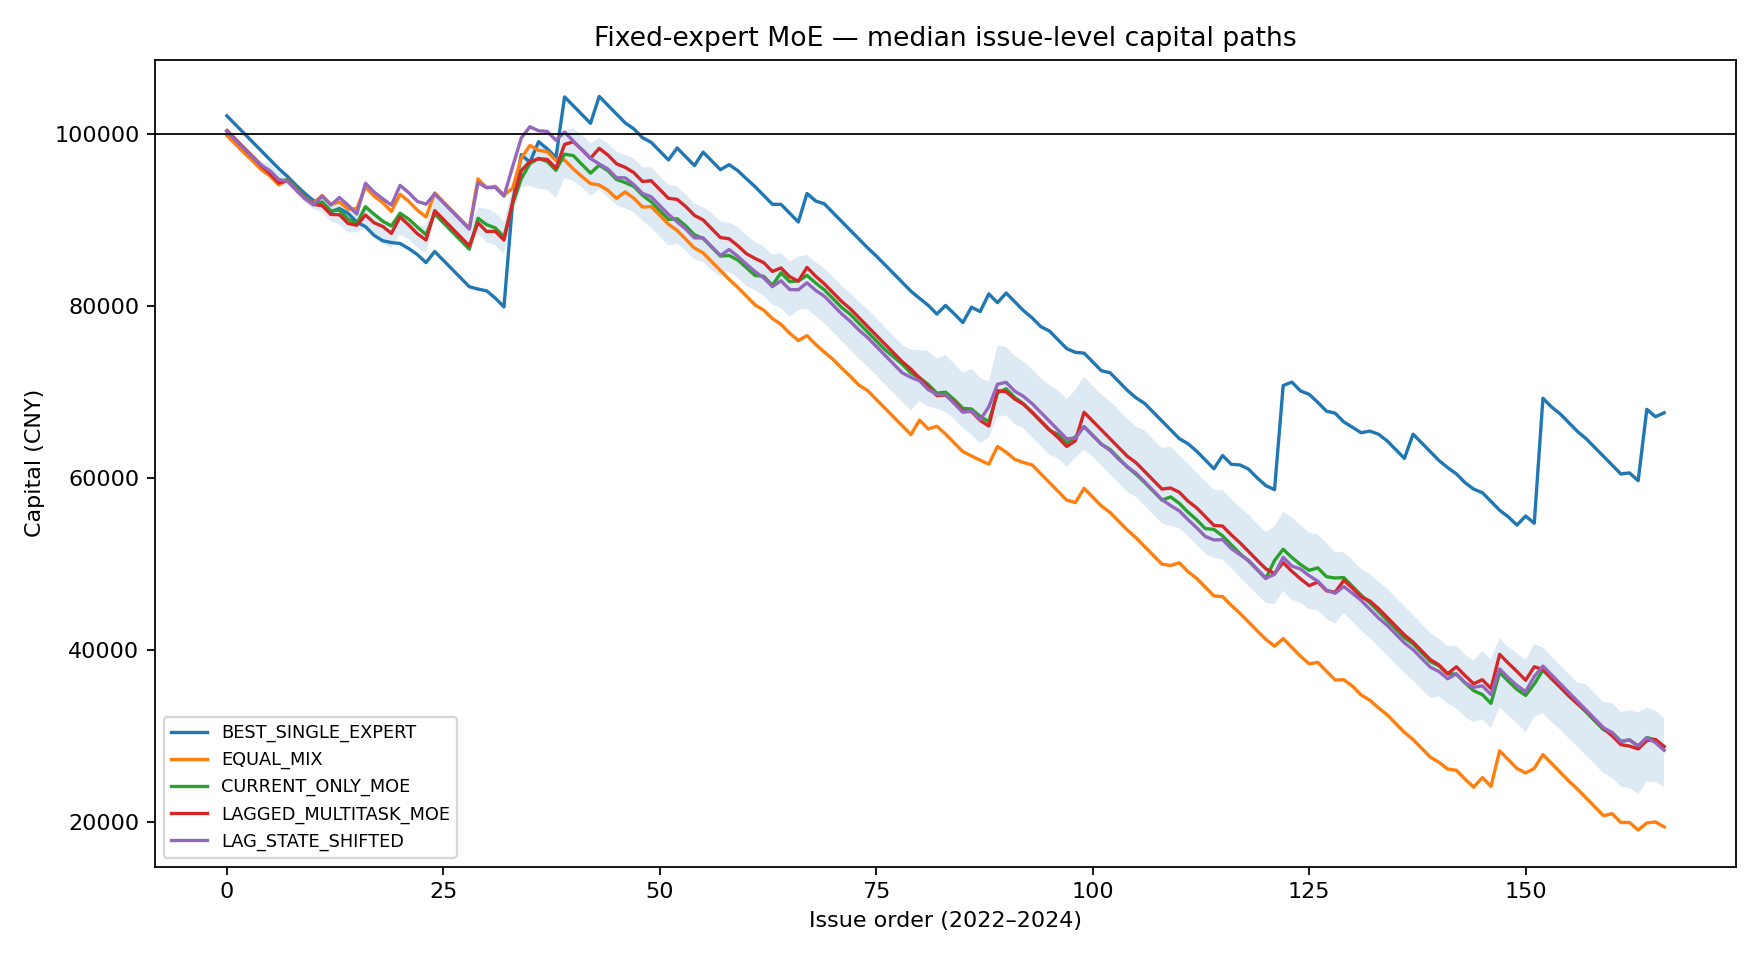

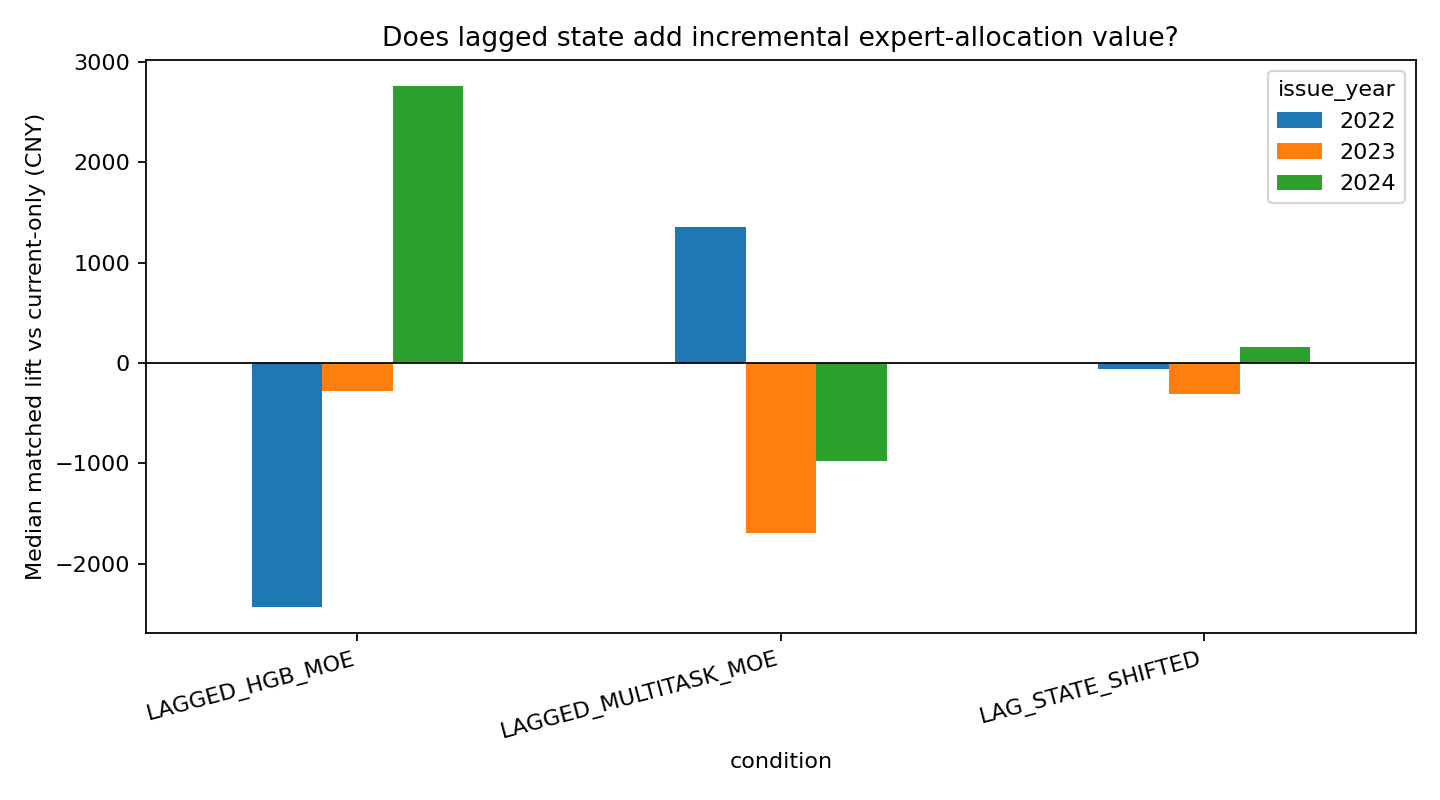

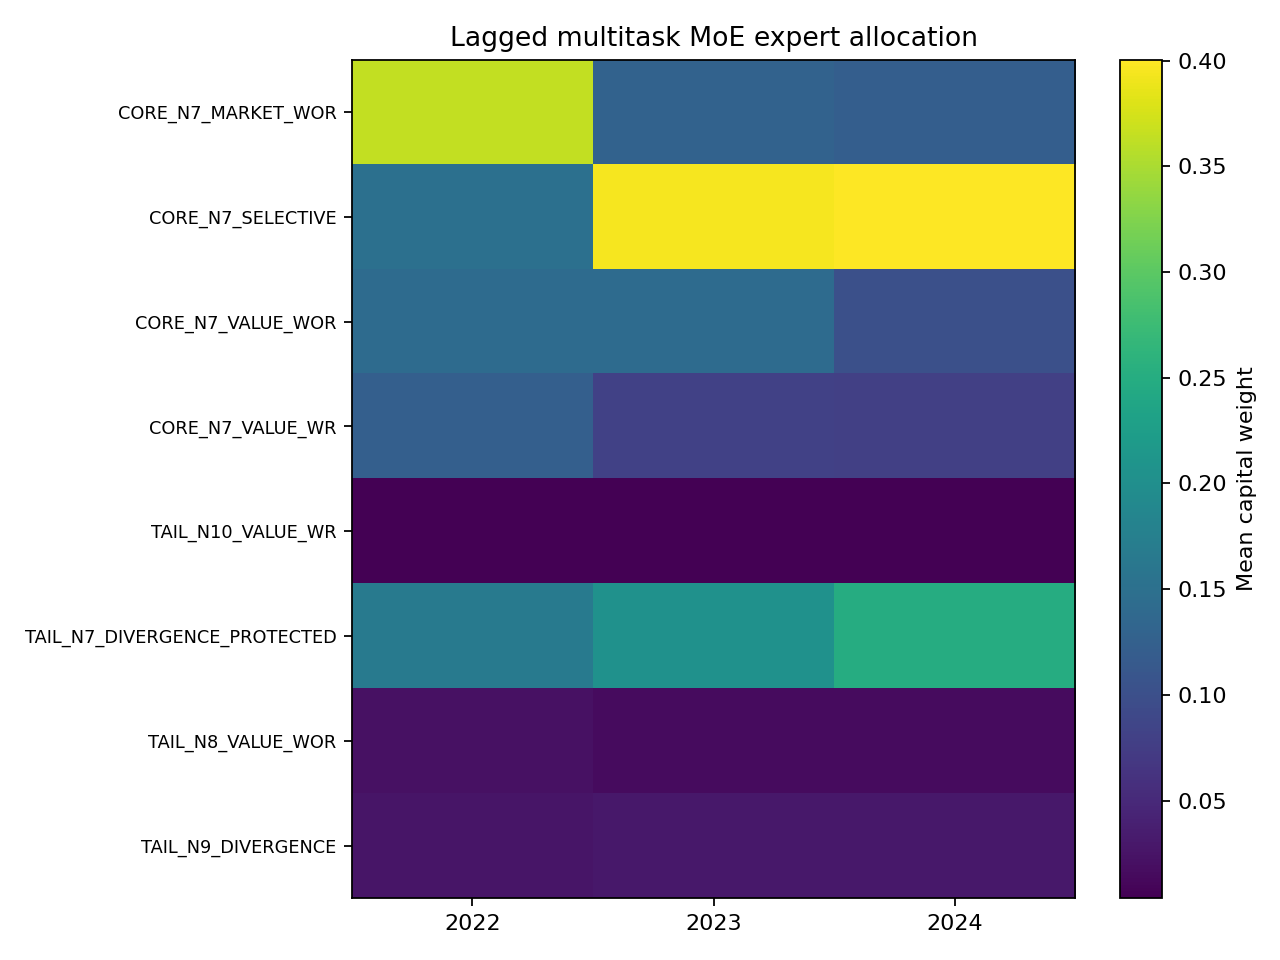

In [6]:
from IPython.display import Image, display
for name in ['issue_332_fixed_expert_capital.png','issue_332_moe_lift.png','issue_332_expert_weights.png']:
    display(Image(filename=str(ROOT/'docs/research/figures'/name)))